In [4]:
def check_stability(mpref, wpref, matching, return_blocking_pairs=False):
    n = len(mpref)
    blocking_pairs = []
 
    for m in range(1, n + 1):
        m_partner = matching[m - 1]
        rank_of_m_partner = mpref[m - 1].index(m_partner) + 1
        for w in range(1, n + 1):
            w_partner = matching.index(w) + 1
            rank_of_w_partner = wpref[w - 1].index(w_partner) + 1
 
            # if (m, w) is not a matching
            if matching[m - 1] != w:
                rank_of_w_for_m = mpref[m - 1].index(w) + 1
                rank_of_m_for_w = wpref[w - 1].index(m) + 1
                if rank_of_m_partner > rank_of_w_for_m and rank_of_w_partner > rank_of_m_for_w:
                    if return_blocking_pairs:
                        bp = (m, w)
                        blocking_pairs.append(bp)
                    else:
                        return False
    
    if return_blocking_pairs:
        return blocking_pairs
    else:
        return True        

In [5]:
import pandas as pd
 
def count_blocking_pairs(preference_sample, manipulated_matching):
    """
    Count the number of blocking pairs in a matching.
    preference_sample = [[mpref], [wpref]]
        mpref[i] = list of women (1-indexed) in order of man i's preference
        wpref[j] = list of men (1-indexed) in order of woman j's preference
    manipulated_matching = list of (man, woman) pairs
    """
    mpref, wpref = preference_sample
    n = len(mpref)
 
    # build quick lookup: partner[m] = w and partner[w] = m
    partner = {}
    for m, w in manipulated_matching:
        partner[m] = w
        partner[w] = m
 
    # build ranking dicts for fast comparison
    man_rank = [{w: rank for rank, w in enumerate(prefs)} for prefs in mpref]
    woman_rank = [{m: rank for rank, m in enumerate(prefs)} for prefs in wpref]
 
    blocking_pairs = 0
    for m in range(1, n+1):
        w_current = partner[m]
        for w in range(1, n+1):
            if w == w_current:
                continue
            # check if m prefers w to current partner
            if man_rank[m-1][w] < man_rank[m-1][w_current]:
                m_current = partner[w]
                # check if w prefers m to her current partner
                if woman_rank[w-1][m] < woman_rank[w-1][m_current]:
                    blocking_pairs += 1
    return blocking_pairs
 
 
def add_blocking_pairs_column(df):
    """
    Adds a column 'blocking_pairs' with the same nested structure
    as 'two_for_one_results', but storing counts instead of manipulation details.
    """
    blocking_results = []
 
    for idx, row in df.iterrows():
        preference_sample = row["preference sample"]
        scenarios = row["two_for_one_results"]
 
        row_results = []
        for agent_scenarios in scenarios:
            agent_results = []
            for benefit_value, manipulated_matching, accomplice_prefs, beneficiary_prefs in agent_scenarios:
                bp_count = count_blocking_pairs(preference_sample, manipulated_matching)
                agent_results.append(bp_count)
            row_results.append(agent_results)
 
        blocking_results.append(row_results)
 
    df["blocking_pairs"] = blocking_results
    return df

Check Mallows Two for One is it stable after manipulation?

In [ ]:
import ast

df = pd.read_csv("mallows_gain.csv")  # Load your CSV file

blocking_results = []

for idx, row in df.iterrows():
    # Parse the original preferences (assumes stored as string)
    mpref, wpref = ast.literal_eval(row["preferences"])
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]
    preference_sample = (mpref, wpref)

    # Parse the two_for_one_results column from string to nested list
    two_for_one_res = ast.literal_eval(row["two_for_one_results"])
    
    row_blocking = []
    for manipulator_results in two_for_one_res:
        manipulator_blocking = []
        for benefit, new_matching, accomplice_prefs, beneficiary_prefs in manipulator_results:
            # Convert new_matching list to list of (man, woman) pairs
            # Here, new_matching is assumed: index = woman-1, value = man
            matching_pairs = [(man, woman) for man, woman in enumerate(new_matching, start=1)]

            bp_count = count_blocking_pairs(preference_sample, matching_pairs)
            manipulator_blocking.append(bp_count)
        row_blocking.append(manipulator_blocking)
    blocking_results.append(row_blocking)

df["blocking_pairs_two_for_one"] = blocking_results
df.to_csv("mallows_gain.csv", index=False)

#print(blocking_results)

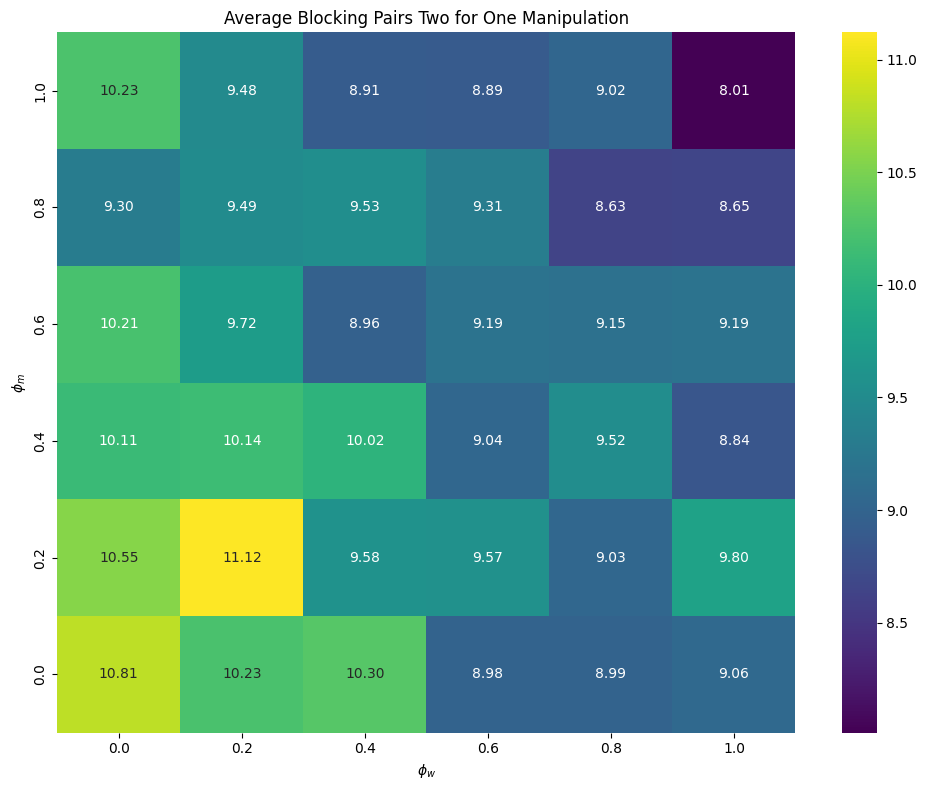

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to flatten nested lists (any depth)
def flatten(lst):
    for el in lst:
        if isinstance(el, list):
            yield from flatten(el)
        else:
            yield el

# Step 1: Compute average blocking pairs per row
df['avg_blocking_pairs'] = df['blocking_pairs_two_for_one'].apply(
    lambda x: np.mean(list(flatten(x))) if x else np.nan
)

# Step 2: Group by phim and phiw, calculate mean of average blocking pairs
agg_df = df.groupby(['phi_m', 'phi_w'])['avg_blocking_pairs'].mean().reset_index()

# Step 3: Pivot for heatmap (phim as rows, phiw as columns)
heatmap_data = agg_df.pivot(index='phi_m', columns='phi_w', values='avg_blocking_pairs')

# Step 4: Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='viridis')
plt.title('Average Blocking Pairs Two for One Manipulation')
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


Accomplice Manipulation

In [14]:
import ast

df = pd.read_csv("mallows_gain.csv")  # Load your CSV file

blocking_results = []

for idx, row in df.iterrows():
    # Parse the original preferences (assumes stored as string)
    mpref, wpref = ast.literal_eval(row["preferences"])
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]
    preference_sample = (mpref, wpref)

    # Parse the two_for_one_results column from string to nested list
    two_for_one_res = ast.literal_eval(row["accomplice_results"])
    
    row_blocking = []
    for manipulator_results in two_for_one_res:
        manipulator_blocking = []
        for benefit, new_matching, accomplice_prefs in manipulator_results:
            # Convert new_matching list to list of (man, woman) pairs
            # Here, new_matching is assumed: index = woman-1, value = man
            matching_pairs = [(man, woman) for man, woman in enumerate(new_matching, start=1)]

            bp_count = count_blocking_pairs(preference_sample, matching_pairs)
            manipulator_blocking.append(bp_count)
        row_blocking.append(manipulator_blocking)
    blocking_results.append(row_blocking)

df["blocking_pairs_accomplice"] = blocking_results
df.to_csv("mallows_gain.csv", index=False)

#print(blocking_results)

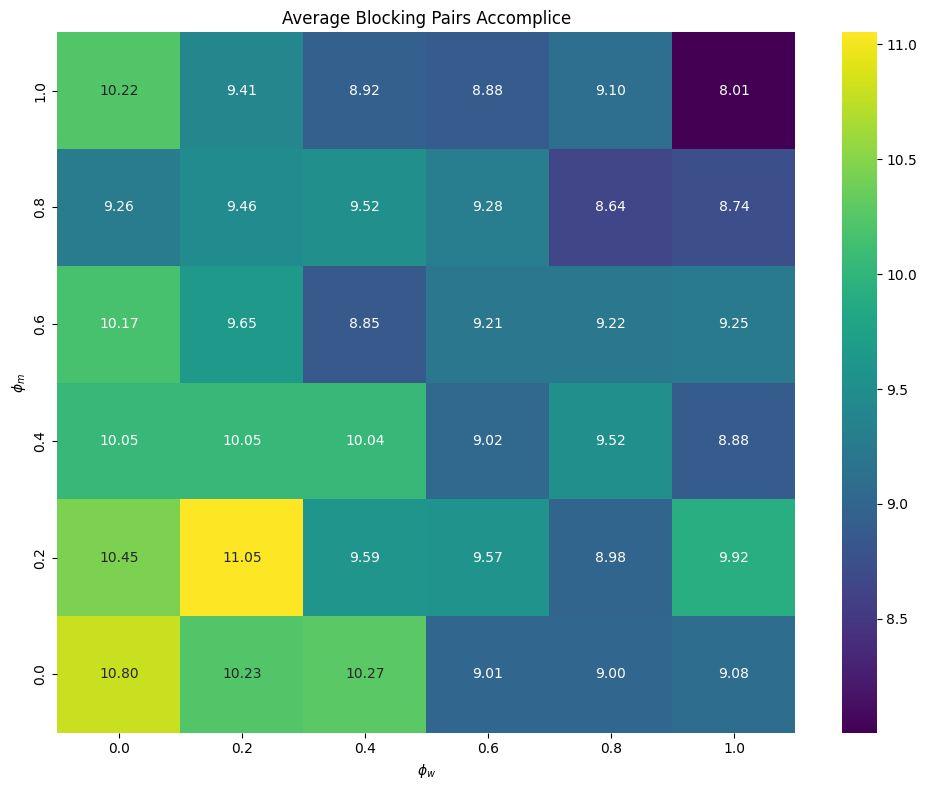

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to flatten nested lists (any depth)
def flatten(lst):
    for el in lst:
        if isinstance(el, list):
            yield from flatten(el)
        else:
            yield el

# Step 1: Compute average blocking pairs per row
df['avg_blocking_pairs'] = df['blocking_pairs_accomplice'].apply(
    lambda x: np.mean(list(flatten(x))) if x else np.nan
)

# Step 2: Group by phim and phiw, calculate mean of average blocking pairs
agg_df = df.groupby(['phi_m', 'phi_w'])['avg_blocking_pairs'].mean().reset_index()

# Step 3: Pivot for heatmap (phim as rows, phiw as columns)
heatmap_data = agg_df.pivot(index='phi_m', columns='phi_w', values='avg_blocking_pairs')

# Step 4: Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='viridis')
plt.title('Average Blocking Pairs Accomplice')
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


Self Manipulation

In [ ]:
import ast

df = pd.read_csv("mallows_gain.csv")  # Load your CSV file

blocking_results = []

for idx, row in df.iterrows():
    # Parse the original preferences (assumes stored as string)
    mpref, wpref = ast.literal_eval(row["preferences"])
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]
    preference_sample = (mpref, wpref)

    # Parse the two_for_one_results column from string to nested list
    two_for_one_res = ast.literal_eval(row["manipulated matchings"])
    
    row_blocking = []
    for manipulator_results in two_for_one_res:
        manipulator_blocking = []
        for benefit, new_matching, accomplice_prefs in manipulator_results:
            # Convert new_matching list to list of (man, woman) pairs
            # Here, new_matching is assumed: index = woman-1, value = man
            matching_pairs = [(man, woman) for man, woman in enumerate(new_matching, start=1)]

            bp_count = count_blocking_pairs(preference_sample, matching_pairs)
            manipulator_blocking.append(bp_count)
        row_blocking.append(manipulator_blocking)
    blocking_results.append(row_blocking)

df["blocking_pairs_accomplice"] = blocking_results
df.to_csv("mallows_gain.csv", index=False)

#print(blocking_results)